In [1]:
lugares = {
    "UNSAAC - Puerta 5": (-13.5222768, -71.9608363),
    "Plaza de Armas": (-13.5167024, -71.9789146),
    "Plaza San Francisco": (-13.5187030, -71.9809920),
    "Paradero Sol de Oro (referencia)": (-13.5319444, -71.9141667)
}

for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

UNSAAC - Puerta 5: lat=-13.5222768, lon=-71.9608363
Plaza de Armas: lat=-13.5167024, lon=-71.9789146
Plaza San Francisco: lat=-13.518703, lon=-71.980992
Paradero Sol de Oro (referencia): lat=-13.5319444, lon=-71.9141667


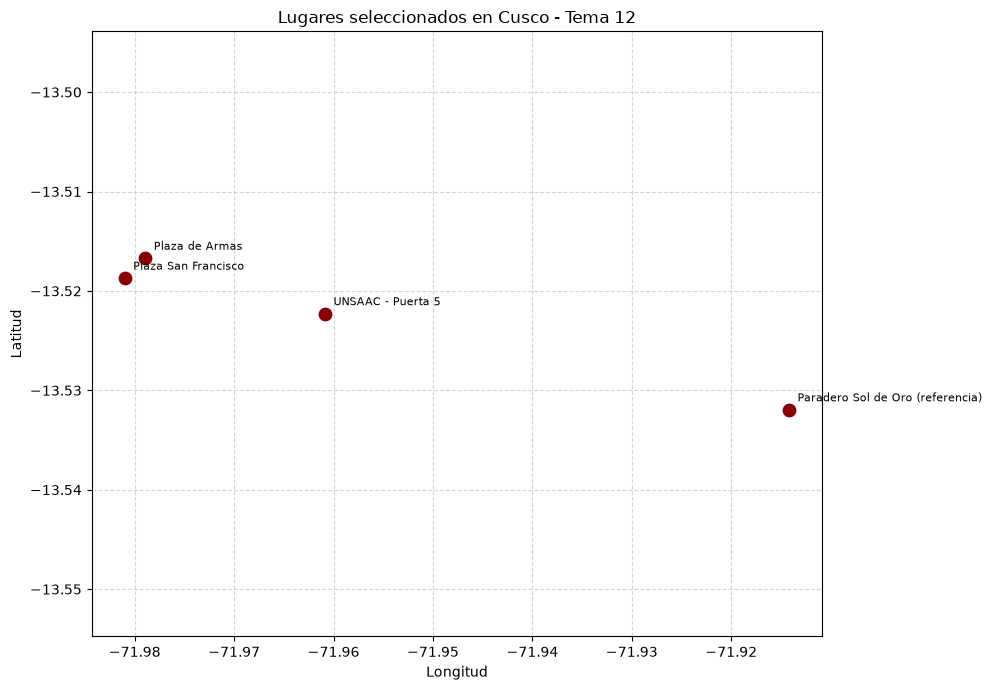

In [3]:
import matplotlib.pyplot as plt

latitudes = [coord[0] for coord in lugares.values()]
longitudes = [coord[1] for coord in lugares.values()]

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(longitudes, latitudes, color="darkred", s=80)

for nombre, (lat, lon) in lugares.items():
    ax.annotate(nombre, (lon, lat), xytext=(6, 6),
                textcoords="offset points", fontsize=8)

ax.set_title("Lugares seleccionados en Cusco - Tema 12")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.savefig("mapa_basico.png", dpi=300)
plt.show()

In [14]:

import math

def distancia_haversine(lat1, lon1, lat2, lon2):

    radio_tierra = 6371.0

    lat1, lon1, lat2, lon2 = map(
        math.radians, [lat1, lon1, lat2, lon2]
    )

    diferencia_lat = lat2 - lat1
    diferencia_lon = lon2 - lon1

    a = (math.sin(diferencia_lat / 2) ** 2
         + math.cos(lat1) * math.cos(lat2)
         * math.sin(diferencia_lon / 2) ** 2)

    angulo = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

    return radio_tierra * angulo
    # Distancia entre la UNSAAC y la Plaza de Armas

distancia = distancia_haversine(
    -13.5222768, -71.9608363,
    -13.5167024, -71.9789146
)

print("La distancia es:", round(distancia, 2), "km")



La distancia es: 2.05 km


In [9]:
nombre_inicial = list(lugares.keys())[0]
lat_inicial, lon_inicial = lugares[nombre_inicial]

for nombre, (lat, lon) in list(lugares.items())[1:]:
    distancia = distancia_haversine(lat_inicial, lon_inicial, lat, lon)
    print(f"{nombre}: {distancia:.2f} km")

Plaza de Armas: 2.05 km
Plaza San Francisco: 2.22 km
Paradero Sol de Oro (referencia): 5.16 km


In [10]:
import itertools

resultados = []
for (nombre1, coord1), (nombre2, coord2) in itertools.combinations(lugares.items(), 2):
    km = distancia_haversine(coord1[0], coord1[1], coord2[0], coord2[1])
    resultados.append((km, nombre1, nombre2))

par_cercano = min(resultados)
par_lejano = max(resultados)

print("Par más cercano:", par_cercano)
print("Par más lejano:", par_lejano)

Par más cercano: (0.3161183915700939, 'Plaza de Armas', 'Plaza San Francisco')
Par más lejano: (7.373067826777661, 'Plaza San Francisco', 'Paradero Sol de Oro (referencia)')


In [21]:
import json

features = []
for nombre, (lat, lon) in lugares.items():
    feature = {
        "type": "Feature",
        "properties": {"nombre": nombre},
        "geometry": {
            "type": "Point",
            "coordinates": [lon, lat]
        }
    }
    features.append(feature)

geojson_mio = {"type": "FeatureCollection", "features": features}

with open("mis_lugares.geojson", "w", encoding="utf-8") as archivo:
    json.dump(geojson_mio, archivo, ensure_ascii=False, indent=4)



In [16]:
with open("mis_lugares.geojson", "r", encoding="utf-8") as archivo:
    geojson_leido = json.load(archivo)

print("Numero de lugares:", len(geojson_leido["features"]))
primer_lugar = geojson_leido["features"][0]
print(primer_lugar["properties"]["nombre"])
print(primer_lugar["geometry"]["coordinates"])

Numero de lugares: 4
UNSAAC - Puerta 5
[-71.9608363, -13.5222768]
